# Looped transformers, step by step

<img src="../../assets/looped/unrolling.gif" width="100%">

A normal transformer stacks **L different blocks** and runs each one once. A **looped transformer** keeps
**one block** and runs it **T times**, feeding its output back in as its input. Depth becomes a loop count:
you buy computation without buying parameters, and you can even choose how long the model "thinks" at test
time.

This notebook is written for an ML engineer who knows what a transformer block is but has never looked
inside a looped one. Every idea is shown three ways - a picture, an equation, and code that runs - and every
claim about behaviour is measured on a real (tiny) trained model, never assumed.

| § | you will |
|---|---|
| 1 | see stacked vs looped side by side and count parameters |
| 2 | rebuild one transformer block from scratch |
| 3 | write a complete looped language model in ~25 lines |
| 4 | understand **weight tying** - one weight, gradients from every pass |
| 5 | understand the **depth embedding** - how pass 1 differs from pass 5 |
| 6 | understand **input injection** - and measure why the naive version hurts |
| 7 | **backprop through the loop** - gradient flow and why clipping matters |
| 8 | prove your scratch model equals the library's `LoopedBackbone`, number for number |
| 9 | train a tiny looped LM and **look inside the loop** (logit lens) |
| 10 | make the model **think longer at test time** - and see what breaks it |

Runs on a CPU in a few minutes. Next notebook: `02_looped_transformer_variants.ipynb` (ACT,
Mixture-of-Recursions, fixed points, relaxed recursion, scratchpads, sharing schedules).

In [1]:
import inspect
import math
import sys
from pathlib import Path

# Make the repo importable when running from notebooks/looped (and HaleBlocks, if it sits next door).
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
for extra in (ROOT / "src", ROOT.parent / "HaleBlocks" / "src"):
    if extra.exists() and str(extra) not in sys.path:
        sys.path.insert(0, str(extra))

import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

import hale_llm.models  # noqa: F401  (registers the paradigms, including variant "looped")
from hale_core.nn.backbones import build_backbone
from hale_core.nn.stacks import LoopedStack, LoopSpec, loop_budget
from hale_llm.visualization.explainers.tokenizer import CharTokenizer
from hale_llm.visualization.looped_films import LoopLab

torch.manual_seed(0)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
tok = CharTokenizer()
print("torch", torch.__version__)

/Users/naveenkumarbasaanitha/Music/HaloDiffusionLLM/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


torch 2.13.0


## 1. The idea in one picture

```mermaid
flowchart LR
  subgraph S["Stacked transformer (L = 4)"]
    direction LR
    x1["tokens"] --> e1["embed"] --> W1["block W1"] --> W2["block W2"] --> W3["block W3"] --> W4["block W4"] --> o1["LM head"]
  end
  subgraph L["Looped transformer (1 block, T = 4)"]
    direction LR
    x2["tokens"] --> e2["embed"] --> W["block W"] --> o2["LM head"]
    W -- "output becomes input<br/>T times" --> W
  end
```

| | stacked | looped |
|---|---|---|
| blocks that exist (parameters) | $L$ | 1 |
| blocks applied per token (compute depth) | $L$ | $T$ |
| can change depth after training? | no | yes - just loop more or less |

Formally the looped model computes

$$ e = \mathrm{embed}(x), \qquad h_t = f_W(h_{t-1}, e, t) \quad (t = 1..T), \qquad \text{logits} = \mathrm{head}(h_T) $$

with **the same** $W$ at every step. Sections 2-6 build $f_W$ piece by piece.

## 2. Refresher: one pre-norm transformer block

```mermaid
flowchart LR
  x["x (B, L, d)"] --> n1["LayerNorm"] --> a["causal self-attention"] --> p1(("+"))
  x --> p1
  p1 --> n2["LayerNorm"] --> m["MLP: Linear → GELU → Linear"] --> p2(("+"))
  p1 --> p2
  p2 --> y["y (B, L, d)"]
```

$$ x' = x + \mathrm{Attn}(\mathrm{LN}_1(x)), \qquad y = x' + \mathrm{MLP}(\mathrm{LN}_2(x')) $$

The two **residual** additions matter a lot for looping: each pass *adds a correction* to the state instead
of replacing it, which keeps a loop of many passes trainable (§7).

In [2]:
class Block(nn.Module):
    """One pre-norm transformer block (the same layout as hale_core's TransformerLayer)."""

    def __init__(self, d: int, heads: int, d_ff: int) -> None:
        super().__init__()
        self.ln1, self.ln2 = nn.LayerNorm(d), nn.LayerNorm(d)
        self.attn = nn.MultiheadAttention(d, heads, batch_first=True)
        self.mlp = nn.Sequential(nn.Linear(d, d_ff), nn.GELU(), nn.Linear(d_ff, d))

    def forward(self, x: torch.Tensor, causal: torch.Tensor) -> torch.Tensor:
        h = self.ln1(x)
        x = x + self.attn(h, h, h, attn_mask=causal, need_weights=False)[0]
        return x + self.mlp(self.ln2(x))


d, heads, d_ff, L = 32, 4, 64, 12
block = Block(d, heads, d_ff)
causal = torch.triu(torch.ones(L, L, dtype=torch.bool), 1)   # True = "may not look here"
x = torch.randn(2, L, d)
print("in ", tuple(x.shape), "-> out", tuple(block(x, causal).shape))
print(f"parameters of one block: {sum(p.numel() for p in block.parameters()):,}")

in  (2, 12, 32) -> out (2, 12, 32)
parameters of one block: 8,544


## 3. A complete looped language model in ~25 lines

Three ingredients turn "call the block T times" into a model that trains well:

$$ h_0 = 0, \qquad h_t = \mathrm{Block}_W\big(\underbrace{h_{t-1}}_{\text{state}} + \underbrace{e}_{\text{input injection}} + \underbrace{E^t}_{\text{depth embedding}}\big), \qquad \text{logits} = \mathrm{head}(\mathrm{LN}(h_T)) $$

* $e$ = token embedding + position embedding, computed **once**;
* $E^t$ tells the block *which pass* it is in (§5);
* re-adding $e$ every pass keeps the input in view however long the loop runs (§6).

In [3]:
def depth_embedding(step: int, d: int) -> torch.Tensor:
    """Sinusoidal code of the loop step (identical to hale_core's LoopDepthEmbedding)."""
    half = d // 2
    freqs = torch.exp(-math.log(10_000.0) * torch.arange(half).float() / half)
    args = float(step + 1) * freqs
    return torch.cat([torch.sin(args), torch.cos(args)])


class TinyLoopedLM(nn.Module):
    """embed -> (one shared Block, T times) -> LN -> LM head (tied to the embedding)."""

    def __init__(self, vocab: int, d: int, heads: int, d_ff: int, max_len: int, n_loops: int) -> None:
        super().__init__()
        self.tok = nn.Embedding(vocab, d)
        self.pos = nn.Parameter(torch.randn(1, max_len, d) * 0.02)
        self.block = Block(d, heads, d_ff)          # <- the ONLY block
        self.ln_out = nn.LayerNorm(d)
        self.n_loops = n_loops

    def forward(self, ids: torch.Tensor, n_loops: int | None = None, keep: list | None = None) -> torch.Tensor:
        n = ids.shape[1]
        causal = torch.triu(torch.ones(n, n, dtype=torch.bool, device=ids.device), 1)
        e = self.tok(ids) + self.pos[:, :n]          # the input, embedded once
        h = torch.zeros_like(e)                      # the state starts empty
        for t in range(n_loops or self.n_loops):
            h = self.block(h + e + depth_embedding(t, e.shape[-1]), causal)
            if keep is not None:
                keep.append(h.detach())              # for looking inside the loop
        return self.ln_out(h) @ self.tok.weight.T    # tied LM head


model = TinyLoopedLM(tok.vocab_size, d, heads, d_ff, max_len=48, n_loops=4)
ids = torch.tensor([tok.encode("the tiny model learned to write")])
states = []
logits = model(ids, keep=states)
print("input ids", tuple(ids.shape), "-> logits", tuple(logits.shape))
for t, h in enumerate(states, 1):
    print(f"after pass {t}: state {tuple(h.shape)}, mean |h| = {h.norm(dim=-1).mean():.2f}")

input ids (1, 31) -> logits (1, 31, 98)
after pass 1: state (1, 31, 32), mean |h| = 7.26
after pass 2: state (1, 31, 32), mean |h| = 14.54
after pass 3: state (1, 31, 32), mean |h| = 21.76
after pass 4: state (1, 31, 32), mean |h| = 28.83


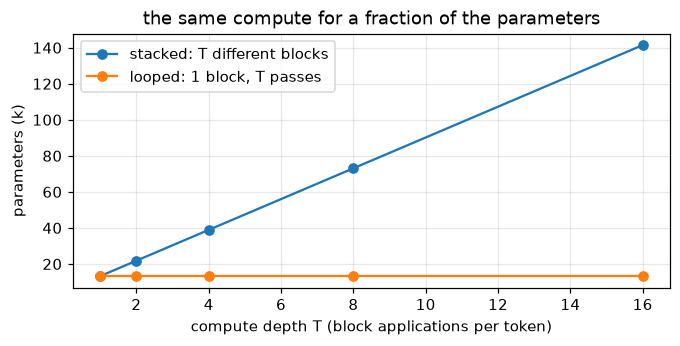

T= 1: looped  13,280 params | stacked  13,280 params (1.0x)
T= 2: looped  13,280 params | stacked  21,824 params (1.6x)
T= 4: looped  13,280 params | stacked  38,912 params (2.9x)
T= 8: looped  13,280 params | stacked  73,088 params (5.5x)
T=16: looped  13,280 params | stacked 141,440 params (10.7x)


In [4]:
# Parameters vs compute: the looped model against a stacked model of the same compute depth.
def n_params(m: nn.Module) -> int:
    return sum(p.numel() for p in m.parameters())

looped_p = n_params(model)
block_p = n_params(model.block)
rows = [(T, looped_p, looped_p + (T - 1) * block_p) for T in (1, 2, 4, 8, 16)]
fig, ax = plt.subplots(figsize=(7, 3))
ax.plot([r[0] for r in rows], [r[2] / 1e3 for r in rows], "o-", label="stacked: T different blocks")
ax.plot([r[0] for r in rows], [r[1] / 1e3 for r in rows], "o-", label="looped: 1 block, T passes")
ax.set(xlabel="compute depth T (block applications per token)", ylabel="parameters (k)",
       title="the same compute for a fraction of the parameters")
ax.legend(); plt.show()
for T, lp, sp in rows:
    print(f"T={T:2d}: looped {lp:7,d} params | stacked {sp:7,d} params ({sp / lp:.1f}x)")

## 4. Weight tying: one $W$, gradients from every pass

Because the same $W$ is used at every pass, its gradient is the **sum** of the gradients each pass would
give it on its own:

$$ \frac{\partial \mathcal{L}}{\partial W} = \sum_{t=1}^{T} \frac{\partial \mathcal{L}}{\partial W^{(t)}} \Big|_{W^{(t)} = W} $$

The cell below makes this literal: it gives every pass its **own copy** of the block's weights
(`torch.func.functional_call`), computes one gradient per copy, and checks that their sum equals the
gradient of the shared weights. It also shows *which passes* push hardest on $W$ - every pass must agree
on one weight that works as a good *iterative* operator, which is what makes looped training different.

sum of per-pass gradients == gradient of the shared weight: True


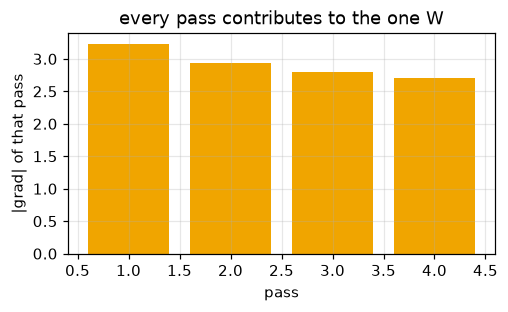

In [5]:
from torch.func import functional_call

torch.manual_seed(0)
target = torch.tensor([tok.encode("he tiny model learned to write!")])  # next characters

def loss_with(per_pass_params):
    n = ids.shape[1]
    causal = torch.triu(torch.ones(n, n, dtype=torch.bool), 1)
    e = model.tok(ids) + model.pos[:, :n]
    h = torch.zeros_like(e)
    for t, params in enumerate(per_pass_params):
        h = functional_call(model.block, params, (h + e + depth_embedding(t, d), causal))
    logits = model.ln_out(h) @ model.tok.weight.T
    return F.cross_entropy(logits[0], target[0])

shared = dict(model.block.named_parameters())
copies = [{k: v.detach().clone().requires_grad_() for k, v in shared.items()} for _ in range(4)]
loss_with(copies).backward()
model.zero_grad(); loss_with([shared] * 4).backward()

name = "mlp.0.weight"
per_pass = [c[name].grad for c in copies]
print("sum of per-pass gradients == gradient of the shared weight:",
      torch.allclose(sum(per_pass), shared[name].grad, atol=1e-6))
norms = [float(sum(c[k].grad.norm() ** 2 for k in c) ** 0.5) for c in copies]
plt.figure(figsize=(5, 2.6)); plt.bar(range(1, 5), norms, color="#f0a500")
plt.xlabel("pass"); plt.ylabel("|grad| of that pass"); plt.title("every pass contributes to the one W"); plt.show()

## 5. The depth embedding: telling pass 1 from pass 5

Without it, the block receives the same kind of input at every pass and cannot behave differently early
(parse) and late (answer). The Universal Transformer (Dehghani et al., 2019) adds a coordinate $E^t$ per
step - here sinusoidal, like position encodings but over *depth*:

$$ E^t_{2i} = \sin\big((t+1)\,\omega_i\big),\quad E^t_{2i+1} = \cos\big((t+1)\,\omega_i\big),\quad \omega_i = 10000^{-i/(d/2)} $$

Sinusoidal codes exist for **any** $t$, so a model can be run for more passes than it was trained with -
but §10 measures that those unseen codes actually *hurt* test-time scaling, and the library's
`recurrent_depth` recipe therefore switches them off.

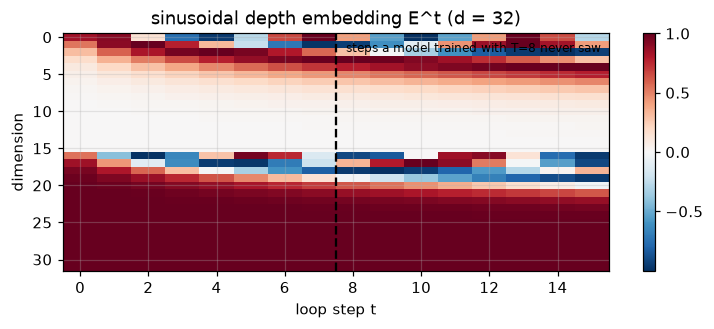

In [6]:
E = torch.stack([depth_embedding(t, 32) for t in range(16)])
fig, ax = plt.subplots(figsize=(8, 2.8))
im = ax.imshow(E.T, aspect="auto", cmap="RdBu_r"); fig.colorbar(im)
ax.set(xlabel="loop step t", ylabel="dimension", title="sinusoidal depth embedding E^t (d = 32)")
ax.axvline(7.5, color="k", ls="--"); ax.text(7.8, 2, "steps a model trained with T=8 never saw", fontsize=8)
plt.show()

## 6. Input injection: keeping the question in view

With $h_t = \mathrm{Block}(h_{t-1})$ alone the input only enters at $t = 0$; long loops tend to drift away
from it. **Input injection** re-feeds it every pass. Three choices exist in the library
(`loop.input_injection`):

| kind | pass input | note |
|---|---|---|
| `none` | $h_{t-1}$ (with $h_0 = e$) | Universal Transformer, MoR, relaxed recursion |
| `add` | $h_{t-1} + e$ | simplest (Yang et al., 2024) - but $e$ piles up in the residual stream |
| `concat` | $W_c\,[h_{t-1}; e]$ | learned adapter (Geiping et al., 2025), initialised to $h + e$ |

Why can `add` hurt? The block's residual connection keeps everything it receives, so after $t$ passes the
state already contains $\approx t$ copies of $e$, and every pass adds one more: the scale of the state grows
with $t$. The cell measures the state size per pass on untrained models, then trains three tiny character
LMs (600 steps each, on this library's own docstrings) and compares held-out bits per character.

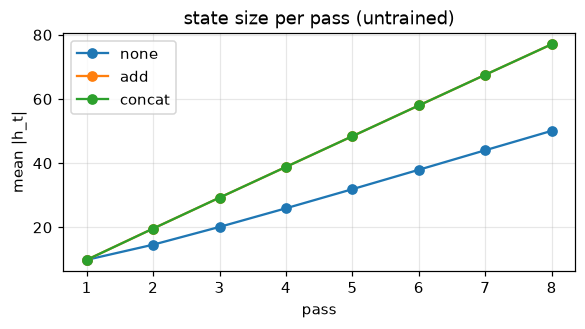

In [7]:
sizes = {}
for kind in ("none", "add", "concat"):
    torch.manual_seed(0)
    bb = build_backbone(tok.vocab_size, arch="looped", d_model=64, n_heads=4, n_layers=1, d_ff=128,
                        max_length=64, loop={"n_loops": 8, "input_injection": kind}).eval()
    with bb.stack.record_passes() as rec, torch.no_grad():
        bb(torch.tensor([tok.encode("looped transformers reuse one block of weights again")]))
    sizes[kind] = [float(h.norm(dim=-1).mean()) for h in rec]
plt.figure(figsize=(6, 2.8))
for kind, v in sizes.items():
    plt.plot(range(1, 9), v, "o-", label=kind)
plt.xlabel("pass"); plt.ylabel("mean |h_t|"); plt.title("state size per pass (untrained)"); plt.legend(); plt.show()

In [8]:
lab = LoopLab()
results = {}
for kind in ("none", "add", "concat"):
    run = lab.train_text({"arch": "looped", "n_layers": 1, "loop": {"n_loops": 4, "input_injection": kind}},
                         steps=600)
    results[kind] = lab.text_loss(run)
base = lab.train_text({"arch": "transformer", "n_layers": 1}, variant="autoregressive", steps=600)
results["(1 block, used once)"] = lab.text_loss(base)
for k, v in results.items():
    print(f"{k:22s} held-out bits/char: {v:.3f}")

none                   held-out bits/char: 3.958
add                    held-out bits/char: 4.376
concat                 held-out bits/char: 3.822
(1 block, used once)   held-out bits/char: 4.069


Lower is better. On this data the learned `concat` adapter and plain `none` let the loop beat the single
block, while naive `add` makes it *worse* than not looping at all - the scale problem above. (With longer
training, 1500 steps, we measured: 1 block 3.33, `add` 4.11, `none` 3.14, `concat` 2.93 - and 4 stacked
blocks 3.00 with 3× the parameters.) This is why the library's presets use `none` or `concat`.

## 7. Backprop through the loop

Training differentiates through all $T$ passes - backprop through time, like an RNN unrolled $T$ steps. The
gradient reaching the input is a product of per-pass Jacobians:

$$ \frac{\partial h_T}{\partial h_0} = \prod_{t=1}^{T} \big(I + J_t\big), \qquad J_t = \frac{\partial\,\Delta_t}{\partial h_{t-1}} $$

where $\Delta_t$ is the correction a pass adds (the residual). The identity term is the "gradient highway"
that keeps long loops trainable; if the $J_t$ are large the product can still explode, which is why
looped training uses **gradient clipping** (`train.grad_clip`), and why `bptt_loops = k` (gradients through
the last $k$ passes only) exists to cap memory at $O(k)$.

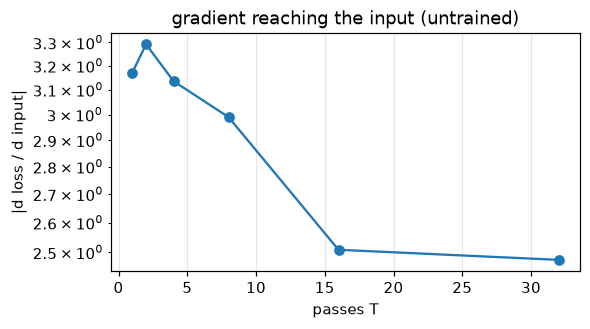

{1: 3.171, 2: 3.292, 4: 3.135, 8: 2.99, 16: 2.508, 32: 2.475}


In [9]:
def input_grad(n_loops: int) -> float:
    torch.manual_seed(0)
    m = TinyLoopedLM(tok.vocab_size, 32, 4, 64, 48, n_loops)
    e_ids = torch.tensor([tok.encode("gradients flow back through every pass")])
    n = e_ids.shape[1]
    emb = (m.tok(e_ids) + m.pos[:, :n]).detach().requires_grad_()
    causal = torch.triu(torch.ones(n, n, dtype=torch.bool), 1)
    h = torch.zeros_like(emb)
    for t in range(n_loops):
        h = m.block(h + emb + depth_embedding(t, 32), causal)
    (m.ln_out(h) @ m.tok.weight.T)[0, -1].logsumexp(-1).backward()
    return float(emb.grad.norm())

Ts = [1, 2, 4, 8, 16, 32]
g = [input_grad(T) for T in Ts]
plt.figure(figsize=(5.5, 2.8)); plt.semilogy(Ts, g, "o-")
plt.xlabel("passes T"); plt.ylabel("|d loss / d input|"); plt.title("gradient reaching the input (untrained)")
plt.show()
print({T: round(v, 3) for T, v in zip(Ts, g)})

## 8. From scratch to the library - and proving they are the same

The library's version of everything above is `LoopedStack` (HaleBlocks), configured by a `LoopSpec`:

```mermaid
flowchart LR
  IDS["token ids"] --> EMB["SequenceBackbone.embed<br/>token + position"]
  EMB --> PRE["prelude layers<br/>(optional, run once)"]
  PRE --> E(("e"))
  E --> INJ["LoopInputInjection<br/>none / add / concat"]
  H0(("h_0")) --> INJ
  INJ --> DEP["+ LoopDepthEmbedding E^t"]
  DEP --> CORE["core layers (shared)<br/>pass_layers(step) schedule"]
  CORE -->|"t < T"| INJ
  CORE --> CODA["coda layers<br/>(optional, run once)"]
  CODA --> OUT["ln_out → LM head"]
```

Here is the heart of it - compare it with `TinyLoopedLM.forward`:

In [10]:
src = inspect.getsource(LoopedStack._loop)
print(src[: src.index("        if route is not None:\n            self.last_stats")])

    def _loop(self, inputs: torch.Tensor, active: torch.Tensor, kw: dict) -> torch.Tensor:
        spec = self.spec
        n_loops = self.num_loops()
        grad_from = n_loops - spec.bptt_loops if self.training and spec.bptt_loops else 0
        state = torch.zeros_like(inputs) if self.injection.starts_from_zero else inputs
        act = self.halting.init_state(state, active) if self.halting is not None else None
        route = self.router(inputs, active, n_loops) if self.router is not None else None
        if route is not None:  # nobody needs more passes than the deepest routed token
            n_loops = max(1, min(n_loops, int(route.depth.max())))
        always = torch.zeros_like(active)
        always[:, : spec.scratch_tokens] = True  # memory slots update on every pass
        check_exit = spec.exit_tolerance is not None and not self.training and act is None
        residual = None
        loops = 0
        for step in range(n_loops):
            previous = state
          

In [11]:
# Build the library model with the same settings and copy its weights into the scratch model.
torch.manual_seed(1)
lib = build_backbone(tok.vocab_size, arch="looped", d_model=32, n_heads=4, n_layers=1, d_ff=64,
                     max_length=48, loop={"n_loops": 4, "input_injection": "add",
                                          "depth_embedding": "sinusoidal"}).eval()
mine = TinyLoopedLM(tok.vocab_size, 32, 4, 64, 48, n_loops=4).eval()
sd = lib.state_dict()
core = "stack.layers.0."
mine.tok.weight.data.copy_(sd["token_emb.weight"]); mine.pos.data.copy_(sd["pos_emb"])
mine.block.attn.load_state_dict({k.removeprefix(core + "attn.attn."): v for k, v in sd.items()
                                 if k.startswith(core + "attn.attn.")})
mine.block.mlp[0].load_state_dict({"weight": sd[core + "ff.net.0.weight"], "bias": sd[core + "ff.net.0.bias"]})
mine.block.mlp[2].load_state_dict({"weight": sd[core + "ff.net.3.weight"], "bias": sd[core + "ff.net.3.bias"]})
for ln in ("ln1", "ln2"):
    getattr(mine.block, ln).load_state_dict({"weight": sd[core + ln + ".weight"], "bias": sd[core + ln + ".bias"]})
mine.ln_out.load_state_dict({"weight": sd["stack.ln_out.weight"], "bias": sd["stack.ln_out.bias"]})

with torch.no_grad():
    a, b = mine(ids), lib(ids)
print("max |scratch - library| =", float((a - b).abs().max()))
assert torch.allclose(a, b, atol=1e-5)
print("✅ the 25-line model and the library compute the same function")

max |scratch - library| = 0.0
✅ the 25-line model and the library compute the same function


## 9. Train a tiny looped LM and look inside the loop

<img src="../../assets/looped/inside_a_pass.gif" width="100%">

`LoopLab` trains a 1-block, 6-pass model (the `universal_transformer` recipe) on four sentences in a few
seconds and records the state after every pass with `LoopedStack.record_passes()`. The **logit lens**
decodes each intermediate state with the final norm + LM head: "what would the model predict if it stopped
after pass $t$?"

sentence: the tiny model learned to write this sentence :)
pass 1: 14/47 right | guesses: hh ttiyymmddllmldarcddttdswrstdtthisssdttdccd::)
pass 2: 31/47 right | guesses: hh tiny mmdelllldartdeto srist ttis ssnttnct :))
pass 3: 42/47 right | guesses: hh tiny model learntd to sritt this senttnce :)l
pass 4: 46/47 right | guesses: he tiny model learned to srite this sentence :)l
pass 5: 46/47 right | guesses: he tiny model learned to srite this sentence :))
pass 6: 45/47 right | guesses: he tiny rodel learned to srite this sentence :))


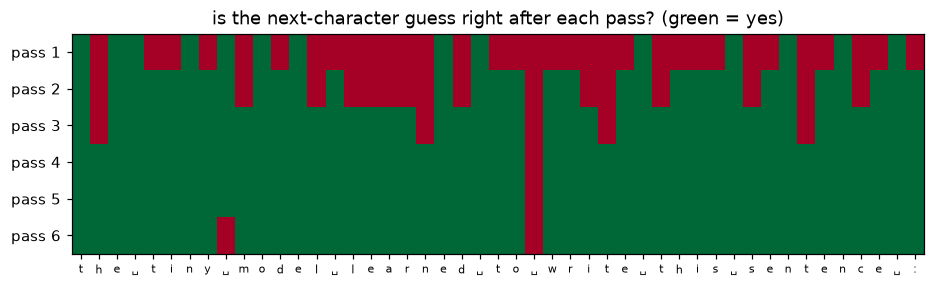

In [12]:
run = lab.train("universal_transformer", n_loops=6)
trace = lab.trace(run)
text = trace.text
right = torch.stack([
    torch.tensor([tok.token(int(trace.lens_ids[t][i, 0])) == text[i + 1] for i in range(len(text) - 1)])
    for t in range(trace.n_passes)
]).float()
print("sentence:", text)
for t in range(trace.n_passes):
    guess = "".join(tok.token(int(i)) for i in trace.lens_ids[t][:, 0])
    print(f"pass {t + 1}: {int(right[t].sum()):2d}/{right.shape[1]} right | guesses: {guess}")
fig, ax = plt.subplots(figsize=(10, 2.6))
ax.imshow(right, cmap="RdYlGn", aspect="auto", vmin=0, vmax=1)
ax.set_xticks(range(len(text) - 1), [c if c != " " else "␣" for c in text[:-1]], fontsize=7)
ax.set_yticks(range(trace.n_passes), [f"pass {t + 1}" for t in range(trace.n_passes)])
ax.set_title("is the next-character guess right after each pass? (green = yes)"); ax.grid(False); plt.show()

Pass 1 mostly echoes the current character; by pass 3-5 nearly every position predicts the next one. The
last red cells are the corpus's genuine choices ("model" vs "robot", "write" vs "spell") - no number of
passes can know which sentence was meant.

## 10. Thinking longer at test time

<img src="../../assets/looped/recurrent_depth.gif" width="100%">

A looped model can run any number of passes at inference: `with loop_budget(model, n): ...`. Whether that
*helps* depends on training. The `recurrent_depth` recipe (Geiping et al., 2025) trains with a **random**
$T \sim U\{2..8\}$ and backprop through the last 4 passes only. Below: two character LMs trained that way on
the docstring corpus - one with the sinusoidal depth embedding, one without - evaluated at budgets 1..24.

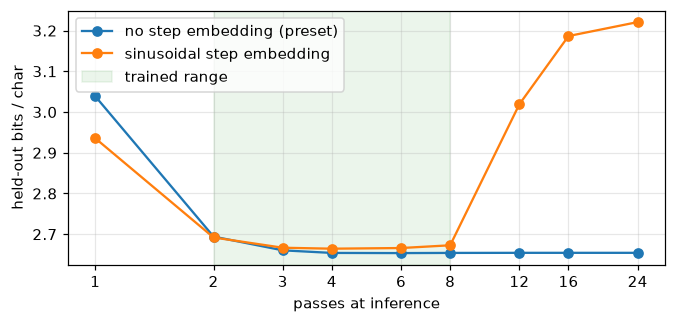

no step embedding (preset) [3.039, 2.694, 2.66, 2.654, 2.654, 2.654, 2.654, 2.654, 2.654]
sinusoidal step embedding [2.936, 2.692, 2.667, 2.664, 2.666, 2.673, 3.019, 3.187, 3.221]


In [13]:
budgets = [1, 2, 3, 4, 6, 8, 12, 16, 24]
curves = {}
for label, extra in (("no step embedding (preset)", {}), ("sinusoidal step embedding", {"depth_embedding": "sinusoidal"})):
    r = lab.train_text({"arch": "looped", "n_layers": 1, "loop": {"preset": "recurrent_depth", **extra}})
    curves[label] = [lab.text_loss(r, b) for b in budgets]
plt.figure(figsize=(7, 3))
for label, v in curves.items():
    plt.plot(budgets, v, "o-", label=label)
plt.axvspan(2, 8, color="green", alpha=0.08, label="trained range")
plt.xscale("log", base=2); plt.xticks(budgets, budgets)
plt.xlabel("passes at inference"); plt.ylabel("held-out bits / char"); plt.legend(); plt.show()
for label, v in curves.items():
    print(label, [round(x, 3) for x in v])

Fewer passes than trained are worse; inside the trained range more passes help up to ~4. Beyond the
trained range, the model **without** a step embedding stays flat - it can safely think longer - while the
sinusoidal version degrades as soon as it meets step codes it never saw. That measurement is why
`LOOP_PRESETS["recurrent_depth"]` sets `depth_embedding: none`.

## Recap

* A looped transformer is one block applied $T$ times: parameters of 1 block, compute of $T$.
* Weight tying sums the gradients of all passes into one $W$ (§4).
* The **depth embedding** tells passes apart - but unseen step codes break test-time scaling (§5, §10).
* **Input injection** keeps the input in view; naive `add` inflates the state, `concat` / `none` train
  better here (§6).
* Backprop goes through every pass; residuals keep it stable, clipping and `bptt_loops` keep it safe (§7).
* Your 25-line model and `hale_core`'s `LoopedBackbone` compute the identical function (§8).

**Cheat sheet**

| concept | where |
|---|---|
| the loop | `HaleBlocks/src/hale_core/nn/stacks/looped/looped_stack.py` (`LoopedStack._loop`) |
| options + presets | `.../stacks/looped/loop_spec.py`, `loop_presets.py` (`LOOP_PRESETS`) |
| depth embedding / injection / ACT / router / per-pass LoRA | `HaleBlocks/src/hale_core/nn/layers/loop/` |
| LM variant | `src/hale_llm/models/models_looped/` (`variant: looped`) |
| configs | `configs/looped/*.yaml`, `configs/looped/variants/*.yaml` |
| animations / lab | `src/hale_llm/visualization/looped_films/` (`hale-llm-loop-films`) |

**Exercises**

1. Remove the depth embedding from `TinyLoopedLM` and train both versions with `LoopLab.train_text`.
2. Replace `h + e` by a learned `nn.Linear(2d, d)` on `[h; e]` (the `concat` adapter) - does it match §6?
3. Plot `mean |h_t|` for 32 passes with and without `sandwich_norm=True`.